<a href="https://colab.research.google.com/github/FedericoHermann/Data_Science_II_Hermann_Federico/blob/main/notebooks/proyecto_final_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Final Data Science II

## Clasificación reproducible de casos malignos y benignos

**Autor:** Federico Hermann  
**Tipo de problema:** clasificación binaria  
**Variable objetivo:** `malignant`, con `1 = maligna`  
**Métrica principal:** ROC-AUC

> **Aclaración metodológica:** este proyecto no es un problema de regresión, sino de clasificación binaria. Aunque uno de los algoritmos utilizados se denomina `LogisticRegression`, la regresión logística se emplea para estimar probabilidades de pertenencia a una clase y producir una clasificación final.

## Introducción

El propósito del proyecto es construir y validar un sistema de Machine Learning capaz de distinguir observaciones malignas y benignas a partir de características diagnósticas del dataset Breast Cancer Wisconsin.

El trabajo no se limita al entrenamiento de un algoritmo. Se implementa un flujo completo, reproducible y auditable que incluye:

1. validación de los datos;
2. análisis exploratorio;
3. ingeniería de atributos;
4. separación estratificada entre entrenamiento y prueba;
5. comparación de modelos;
6. optimización de hiperparámetros;
7. validación cruzada anidada;
8. selección de un umbral operativo;
9. evaluación final sobre datos reservados;
10. explicabilidad mediante SHAP;
11. persistencia de los modelos;
12. controles automáticos de consistencia.

La clase positiva se define como **maligna**, dado que el error de mayor interés consiste en clasificar un caso maligno como benigno. Antes de evaluar el conjunto de prueba se establece un costo relativo de **5 a 1** para falsos negativos frente a falsos positivos.

## Resultados esperados

Se espera obtener:

- un modelo capaz de discriminar correctamente entre observaciones benignas y malignas;
- una comparación objetiva entre Logistic Regression, XGBoost baseline y XGBoost optimizado;
- una selección metodológica realizada sin consultar el conjunto de prueba;
- un umbral operativo alineado con el costo de los errores;
- métricas, visualizaciones y explicaciones interpretables;
- evidencia de que el código, los resultados y el informe son consistentes.

Este proyecto tiene fines educativos y no constituye una herramienta clínica ni un sistema de diagnóstico.

In [8]:
from pathlib import Path
import os, subprocess, sys

REPO_URL = "https://github.com/FedericoHermann/Data_Science_II_Hermann_Federico.git"
IN_COLAB = Path("/content").exists() and "google.colab" in sys.modules
if IN_COLAB:
    project = Path("/content/Data_Science_II_Hermann_Federico")
    if project.exists():
        subprocess.run(["git", "-C", str(project), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", REPO_URL, str(project)], check=True)
else:
    candidates=[Path.cwd(), *Path.cwd().parents]
    project=next((p for p in candidates if (p/"src/project_pipeline.py").is_file()), None)
    if project is None:
        raise FileNotFoundError("No se encontró la raíz del repositorio")
os.chdir(project)
print("Proyecto:", Path.cwd())

Proyecto: /content/Data_Science_II_Hermann_Federico


In [9]:
from importlib.metadata import (
    PackageNotFoundError,
    version
)
import subprocess
import sys
import time


# ------------------------------------------------------------
# PAQUETES NECESARIOS
# ------------------------------------------------------------

REQUIRED_PACKAGES = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "scipy": "scipy",
    "scikit-learn": "sklearn",
    "xgboost": "xgboost",
    "shap": "shap",
    "joblib": "joblib"
}


# ------------------------------------------------------------
# DETECCIÓN DE PAQUETES INSTALADOS
# ------------------------------------------------------------

missing_packages = []

print("VERIFICACIÓN DE DEPENDENCIAS")
print("=" * 60)

for distribution_name in REQUIRED_PACKAGES:

    try:
        installed_version = version(
            distribution_name
        )

        print(
            f"OK   {distribution_name}: "
            f"{installed_version}"
        )

    except PackageNotFoundError:

        print(
            f"MISS {distribution_name}: "
            "no instalado"
        )

        missing_packages.append(
            distribution_name
        )


# ------------------------------------------------------------
# INSTALACIÓN SELECTIVA
# ------------------------------------------------------------

if missing_packages:

    print(
        "\nSe instalarán únicamente "
        "los paquetes faltantes:"
    )

    for package_name in missing_packages:
        print(
            f"- {package_name}"
        )

    installation_start = time.perf_counter()

    command = [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--prefer-binary",
        "--disable-pip-version-check"
    ] + missing_packages

    print(
        "\nEjecutando:"
    )

    print(
        " ".join(command)
    )

    subprocess.run(
        command,
        check=True
    )

    installation_seconds = (
        time.perf_counter()
        - installation_start
    )

    print(
        "\nInstalación completada en "
        f"{installation_seconds:.1f} segundos."
    )

else:

    print(
        "\nTodas las dependencias necesarias "
        "ya están disponibles."
    )

    print(
        "No fue necesario ejecutar pip install."
    )


# ------------------------------------------------------------
# VERIFICACIÓN FINAL
# ------------------------------------------------------------

print(
    "\nVERIFICACIÓN FINAL"
)

print(
    "=" * 60
)

verification_errors = []

for distribution_name in REQUIRED_PACKAGES:

    try:
        installed_version = version(
            distribution_name
        )

        print(
            f"OK   {distribution_name}: "
            f"{installed_version}"
        )

    except PackageNotFoundError:

        verification_errors.append(
            distribution_name
        )

        print(
            f"ERROR {distribution_name}: "
            "no disponible"
        )


if verification_errors:

    raise RuntimeError(
        "No fue posible preparar estas dependencias: "
        + ", ".join(
            verification_errors
        )
    )


print(
    "\nEntorno preparado correctamente."
)

VERIFICACIÓN DE DEPENDENCIAS
OK   numpy: 2.4.6
OK   pandas: 2.2.3
OK   matplotlib: 3.10.0
OK   scipy: 1.16.3
OK   scikit-learn: 1.6.1
OK   xgboost: 3.4.1
OK   shap: 0.54.1
OK   joblib: 1.6.0

Todas las dependencias necesarias ya están disponibles.
No fue necesario ejecutar pip install.

VERIFICACIÓN FINAL
OK   numpy: 2.4.6
OK   pandas: 2.2.3
OK   matplotlib: 3.10.0
OK   scipy: 1.16.3
OK   scikit-learn: 1.6.1
OK   xgboost: 3.4.1
OK   shap: 0.54.1
OK   joblib: 1.6.0

Entorno preparado correctamente.


## 1. Formulación del problema

- Tarea: clasificación binaria.
- Objetivo: `malignant`, con `1 = maligna`.
- Métrica principal: ROC-AUC.
- Costos previos a prueba: falso negativo = 5; falso positivo = 1.
- El conjunto de prueba permanece aislado hasta la evaluación final.

## 2. EDA e ingeniería de atributos

El pipeline valida datos, genera resúmenes, faltantes, outliers, distribuciones, boxplots y correlaciones. La ingeniería crea tres ratios dentro del pipeline para evitar fuga de información.

## Entrenamiento, optimización y selección

El entrenamiento se encuentra integrado en el pipeline canónico `src/project_pipeline.py`.

El flujo realiza:

1. la carga y validación de los datos;
2. la separación estratificada entre entrenamiento y prueba;
3. la ingeniería de atributos dentro de pipelines;
4. el entrenamiento de Logistic Regression;
5. el entrenamiento de un XGBoost baseline;
6. la optimización de XGBoost mediante GridSearchCV;
7. la evaluación de los procedimientos mediante validación cruzada anidada;
8. la selección del modelo según una regla definida previamente;
9. la selección del umbral con predicciones out-of-fold;
10. el ajuste final utilizando todo el conjunto de entrenamiento;
11. la evaluación única sobre el conjunto de prueba.

No se entrena un modelo alternativo por fuera del pipeline porque eso duplicaría la lógica y podría generar diferencias entre el código mostrado, el modelo persistido y los resultados informados.

In [15]:
import subprocess
import sys
import time

print(
    "Compilando el pipeline..."
)

subprocess.run(
    [
        sys.executable,
        "-m",
        "py_compile",
        "src/project_pipeline.py"
    ],
    check=True
)

print(
    "Compilación superada."
)

print(
    "\nEjecutando entrenamiento, "
    "optimización y evaluación..."
)

execution_start = time.perf_counter()

subprocess.run(
    [
        sys.executable,
        "src/project_pipeline.py"
    ],
    check=True
)

execution_seconds = (
    time.perf_counter()
    - execution_start
)

print(
    "\nPipeline completo ejecutado "
    f"en {execution_seconds:.1f} segundos."
)

Compilando el pipeline...
Compilación superada.

Ejecutando entrenamiento, optimización y evaluación...

Pipeline completo ejecutado en 36.7 segundos.


## Funcionamiento integral del pipeline

El pipeline implementa el ciclo completo del proyecto:

### Preparación y validación

- Carga el dataset Breast Cancer Wisconsin.
- Define `malignant = 1` como clase positiva.
- Verifica valores faltantes, columnas duplicadas y valores no finitos.
- Genera un snapshot reproducible y un diccionario de datos.

### Análisis exploratorio

- Describe estadísticamente las variables.
- Analiza la distribución de clases.
- Identifica posibles outliers mediante IQR.
- Genera histogramas, boxplots y una matriz de correlación.

### Ingeniería de atributos

Crea dentro del pipeline:

- `area_perimeter_ratio`;
- `worst_to_mean_radius_ratio`;
- `concavity_compactness_ratio`.

### Modelado

Compara:

- Logistic Regression;
- XGBoost baseline;
- XGBoost optimizado mediante GridSearchCV.

### Validación

- Aplica validación cruzada anidada.
- Calcula ROC-AUC, PR-AUC, accuracy, precision, recall y F1-score.
- Compara las métricas de entrenamiento y validación.
- Registra la dispersión entre folds.

### Selección

- Selecciona el modelo mediante una regla previa.
- Considera equivalentes los modelos dentro de una tolerancia práctica.
- Utiliza recall, estabilidad y tiempo como criterios de desempate.
- Selecciona el umbral mediante probabilidades out-of-fold.

### Evaluación final

- Utiliza el conjunto de prueba una única vez.
- Calcula las métricas finales.
- Genera curvas ROC y Precision-Recall.
- Genera la matriz de confusión.
- Cuantifica falsos negativos, falsos positivos y costo ponderado.

### Explicabilidad

- Utiliza XGBoost como modelo explicativo complementario.
- Genera importancia global SHAP.
- Genera un gráfico beeswarm.
- Produce una explicación local.
- Evalúa la estabilidad de las variables importantes.

### Persistencia y auditoría

- Guarda los modelos con joblib.
- Recarga el modelo final.
- Verifica que las probabilidades se conserven.
- Genera informes, tablas, gráficos y controles automáticos.

In [10]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "py_compile", "src/project_pipeline.py"], check=True)
subprocess.run([sys.executable, "src/project_pipeline.py"], check=True)
print("Pipeline completo ejecutado correctamente.")

Pipeline completo ejecutado correctamente.


## 4. Resultados y criterio de decisión

In [11]:
import json
import pandas as pd
from IPython.display import display, Markdown, Image
summary=json.loads(Path("artifacts/final_summary.json").read_text(encoding="utf-8"))
cv=pd.read_csv("reports/nested_cv_results.csv")
selection=pd.read_csv("reports/model_selection_table.csv")
test=pd.read_csv("reports/test_results.csv")
display(cv)
display(selection)
display(test)
display(Markdown(Path("reports/final_report.md").read_text(encoding="utf-8")))

,model,elapsed_seconds,outer_roc_auc_mean,outer_roc_auc_std,train_roc_auc_mean,gap_roc_auc,outer_pr_auc_mean,outer_pr_auc_std,train_pr_auc_mean,gap_pr_auc,...,train_precision_mean,gap_precision,outer_recall_mean,outer_recall_std,train_recall_mean,gap_recall,outer_f1_mean,outer_f1_std,train_f1_mean,gap_f1
0,LogisticRegression,0.345391,0.995666,0.003872,0.998439,0.002773,0.994150,0.004972,0.997883,0.003733,...,0.985207,0.025973,0.958824,0.049215,0.976471,0.017647,0.958352,0.023269,0.980806,0.022455
1,XGBoostGridSearch,18.631596,0.993911,0.004968,1.000000,0.006089,0.992049,0.005873,1.000000,0.007951,...,1.000000,0.029958,0.947059,0.024608,1.000000,0.052941,0.958291,0.019545,1.000000,0.041709
2,XGBoostBaseline,1.024746,0.993705,0.004692,1.000000,0.006295,0.991699,0.005984,1.000000,0.008301,...,1.000000,0.024075,0.941176,0.036022,1.000000,0.058824,0.957928,0.024587,1.000000,0.042072


,perspective,criterion,selected_method,evidence,defines_selection
0,Selección metodológica,ROC-AUC CV máximo con tolerancia 0.002; desemp...,LogisticRegression,ROC-AUC=0.995666 ± 0.003872,True
1,Umbral operativo,"Costo FN:FP=5:1, recall mínimo=0.95",LogisticRegression,Umbral OOF=0.31,True
2,Evaluación final,Prueba aislada; no reabre la selección,LogisticRegression,ROC-AUC=0.995370; PR-AUC=0.993151; FN=2; FP=2,False


,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,true_negatives,false_positives,false_negatives,true_positives,weighted_error_cost
0,LogisticRegression,0.31,0.964912,0.952381,0.952381,0.952381,0.99537,0.993151,70,2,2,40,12


# Informe final

## Formulación

Clasificación binaria. Variable objetivo: `malignant` (1 = maligna). Métrica principal: ROC-AUC. Costos definidos antes de prueba: FN=5, FP=1.

## Selección metodológica

- Modelo: **LogisticRegression**.
- ROC-AUC CV: **0.995666 ± 0.003872**.
- Umbral OOF: **0.31**.

## Prueba aislada

- ROC-AUC: **0.995370**.
- PR-AUC: **0.993151**.
- Accuracy: **0.964912**.
- Precision: **0.952381**.
- Recall: **0.952381**.
- F1: **0.952381**.
- FN: **2**.
- FP: **2**.
- Costo ponderado: **12**.

## Explicabilidad

SHAP se calculó sobre el XGBoost optimizado como modelo explicativo complementario. Si el modelo final seleccionado es otro, SHAP no se presenta como explicación del modelo final. Las contribuciones son predictivas, no causales.

## Limitaciones

Dataset educativo y moderado. Se requiere validación externa, calibración, revisión experta y evaluación de impacto antes de cualquier uso real.


## 5. Visualizaciones de evaluación

figures/model_comparison.png


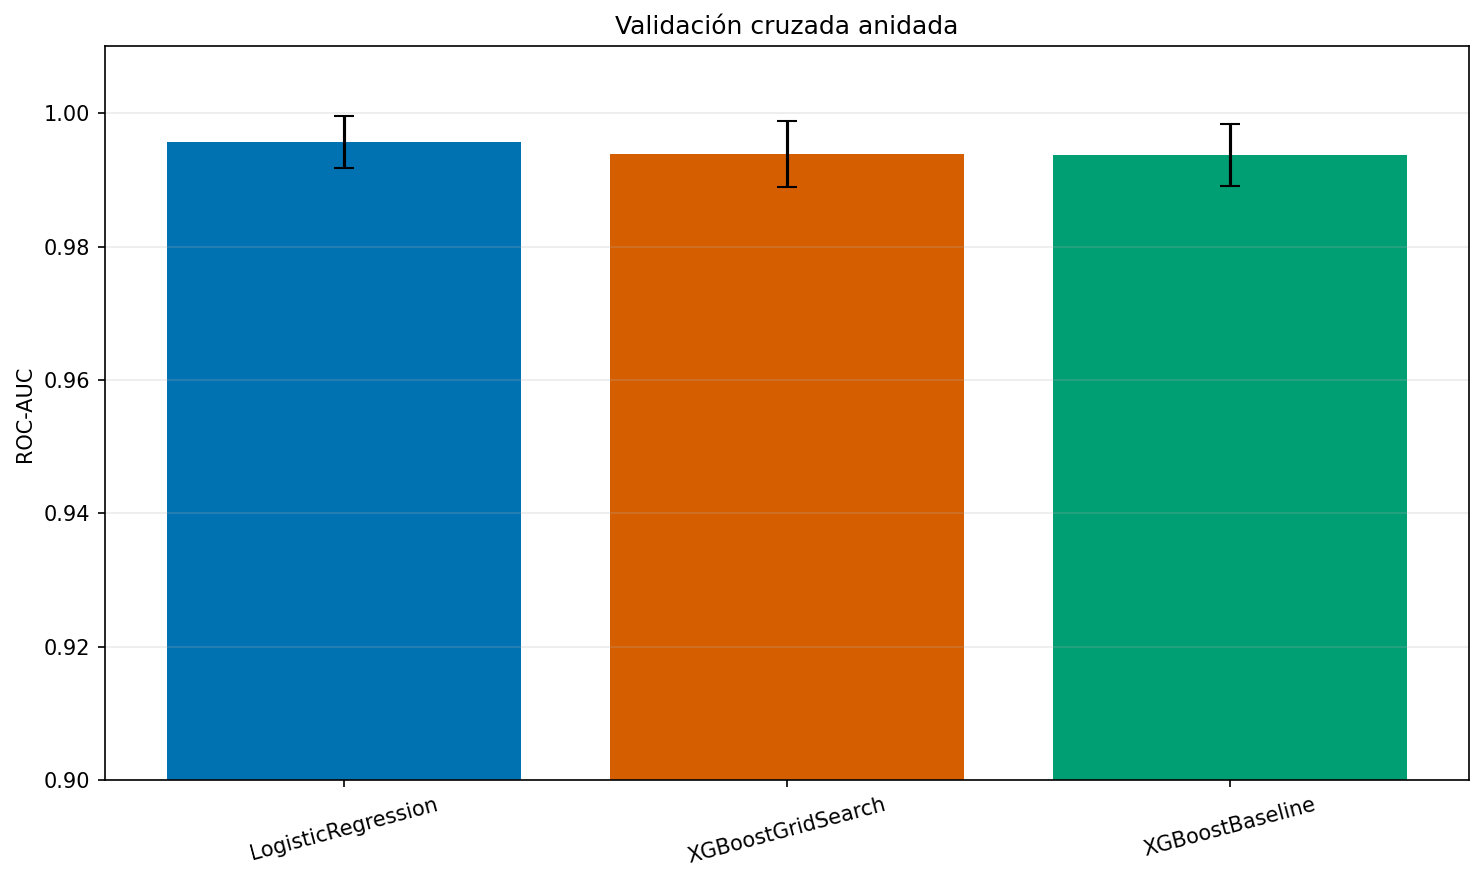

figures/roc_pr_curves.png


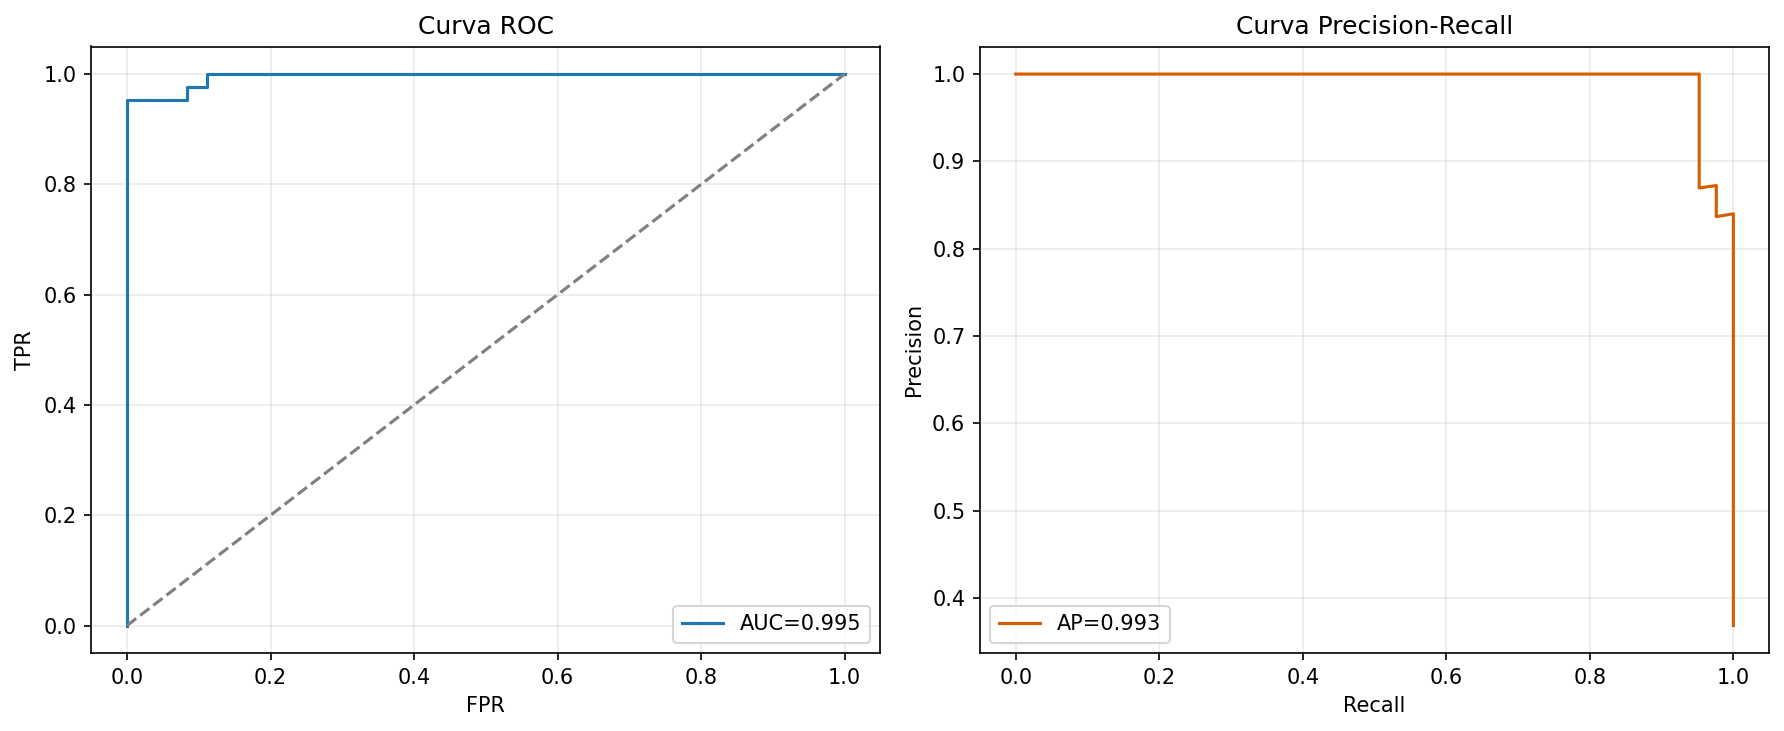

figures/confusion_matrix.png


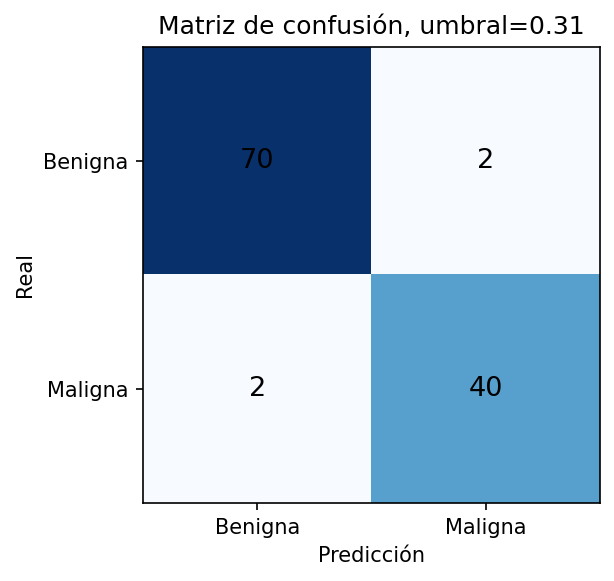

In [12]:
for path in ["figures/model_comparison.png","figures/roc_pr_curves.png","figures/confusion_matrix.png"]:
    print(path); display(Image(filename=path))

## 6. Explicabilidad SHAP

SHAP se aplica al XGBoost optimizado como modelo explicativo complementario. Si el modelo seleccionado es distinto, estas explicaciones no se atribuyen al modelo final.

figures/shap_importance.png


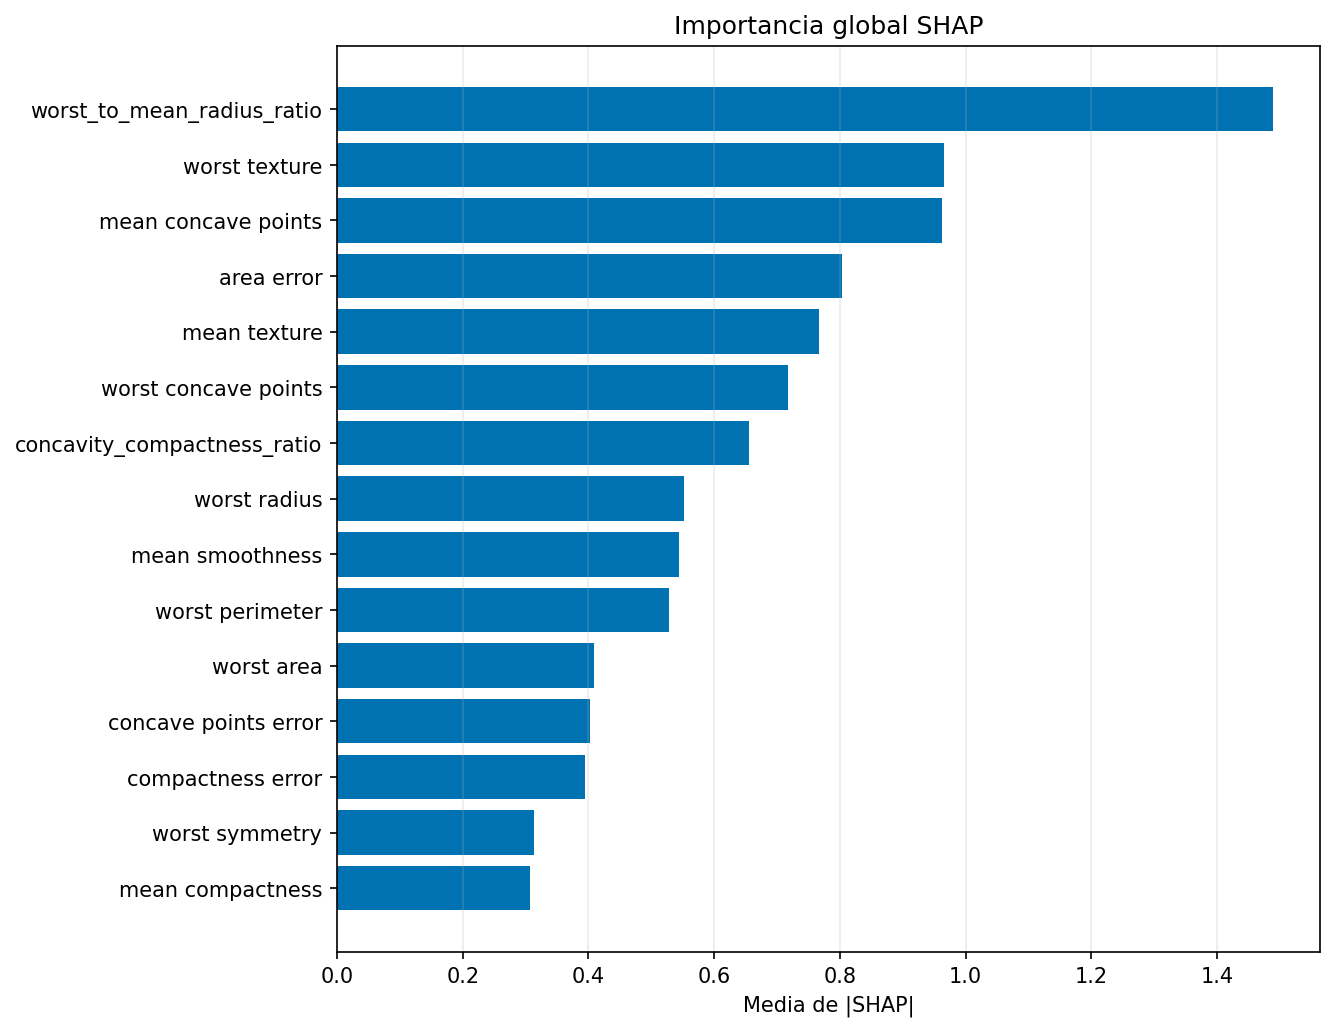

figures/shap_beeswarm.png


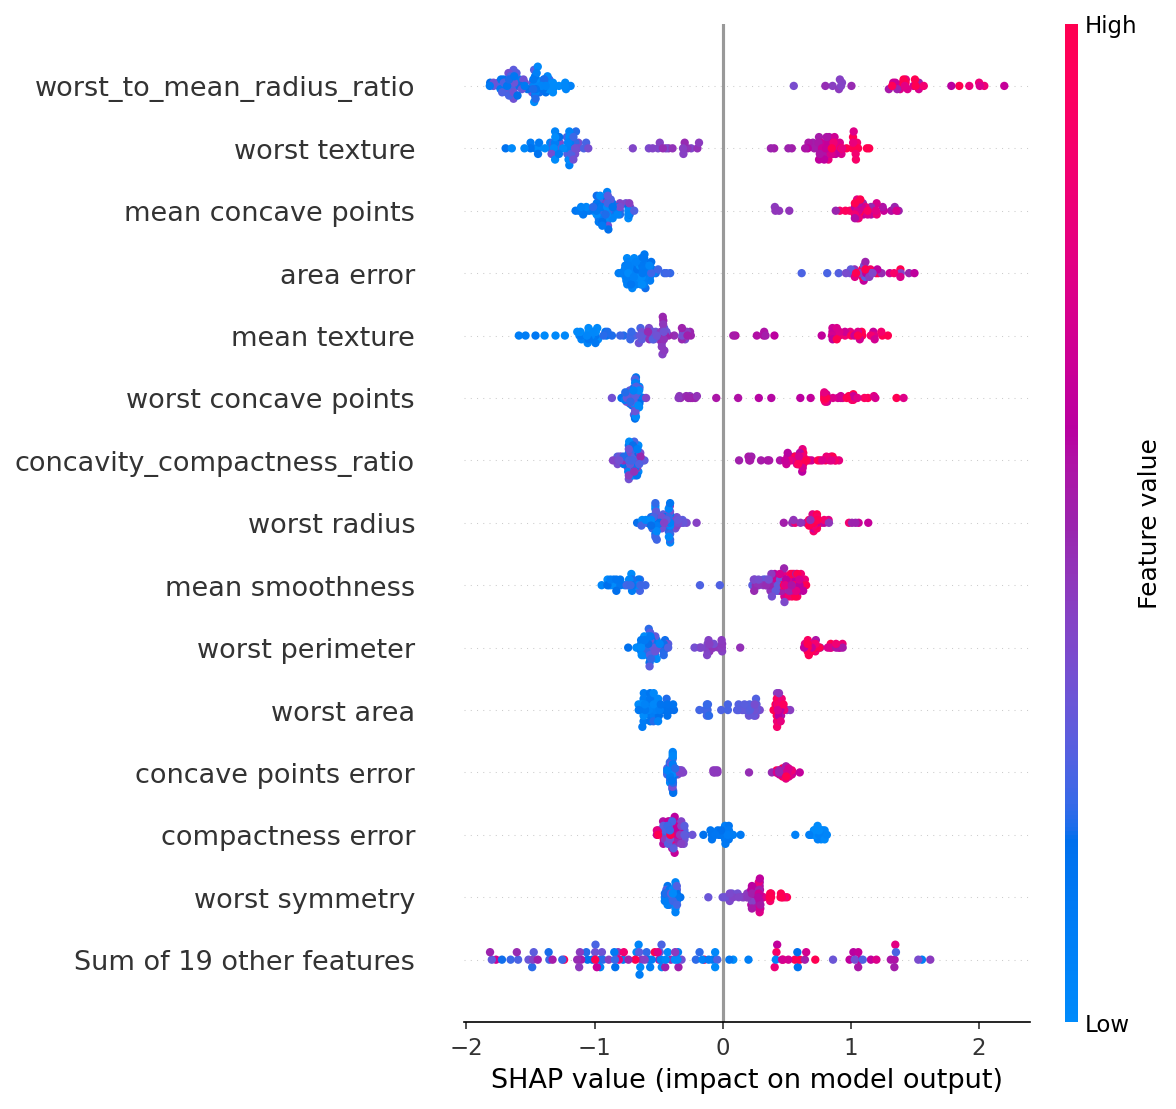

figures/shap_local_explanation.png


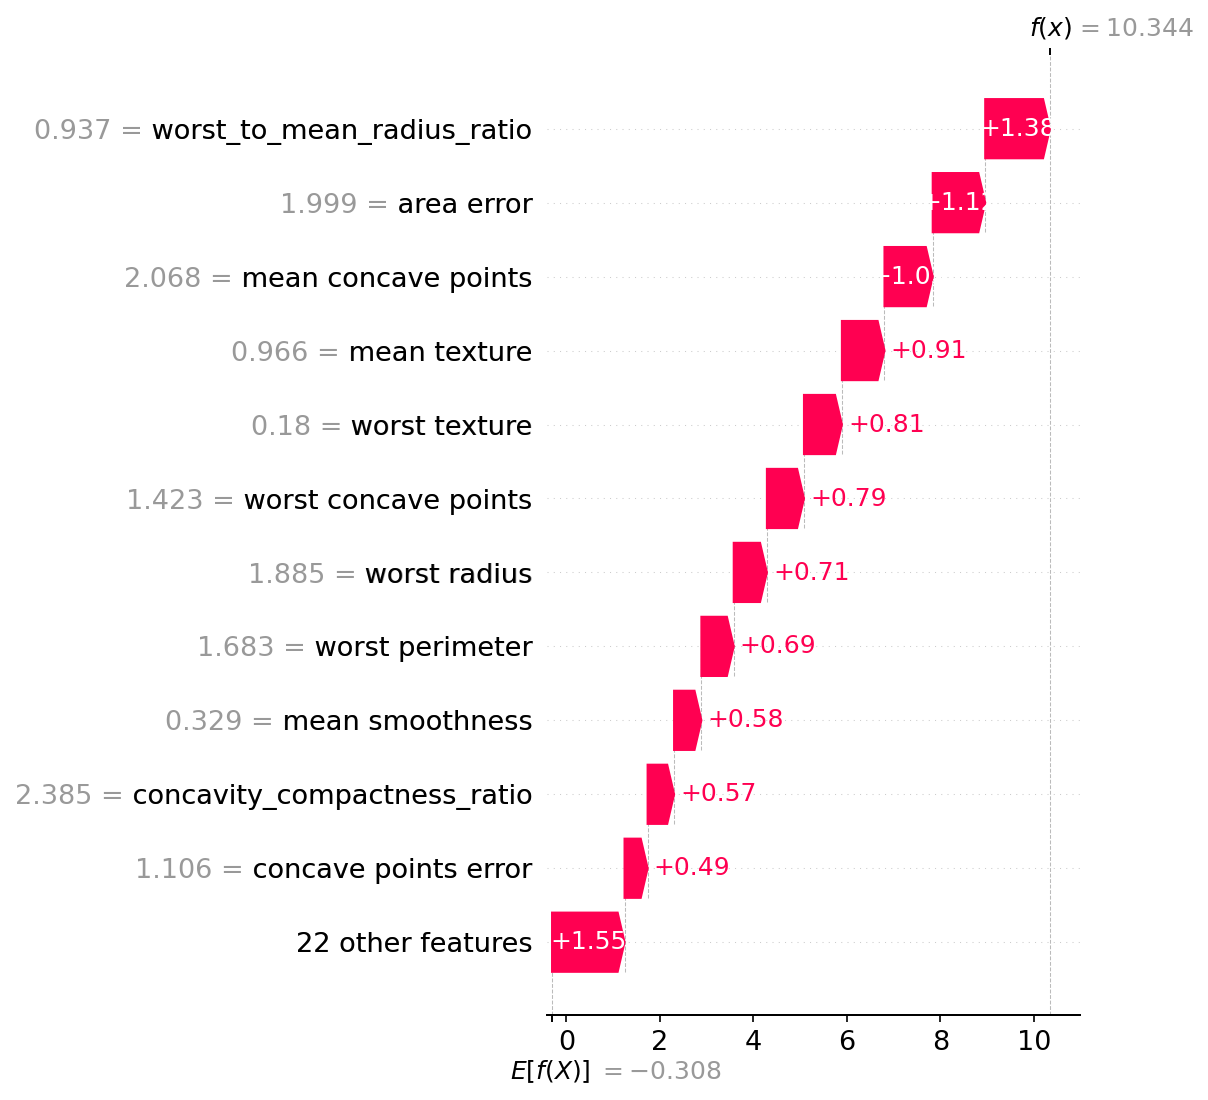

,feature,mean_importance,std_importance,mean_rank,top10_frequency
0,worst_to_mean_radius_ratio,1.280229,0.200341,1.2,1.0
1,mean concave points,0.943672,0.284281,3.4,1.0
2,worst texture,0.775643,0.279249,5.0,1.0
3,worst perimeter,0.762058,0.258622,5.4,1.0
4,mean texture,0.788992,0.298691,5.6,0.8
5,concavity_compactness_ratio,0.692185,0.137338,5.8,1.0
6,worst concave points,0.610602,0.177348,6.4,1.0
7,area error,0.578828,0.250986,7.0,0.8
8,worst area,0.412757,0.050113,10.2,0.6
9,worst radius,0.438521,0.210272,10.2,0.6


In [13]:
for path in ["figures/shap_importance.png","figures/shap_beeswarm.png","figures/shap_local_explanation.png"]:
    print(path); display(Image(filename=path))
display(pd.read_csv("reports/shap_stability.csv").head(15))

## 7. Auditoría final

Verificación de calidad de ejecución

In [14]:
subprocess.run([sys.executable, "scripts/audit_project.py"], check=True)
checks=json.loads(Path("artifacts/consistency_checks.json").read_text(encoding="utf-8"))
display(pd.DataFrame(list(checks.items()), columns=["control","resultado"]))
assert all(checks.values())
print("Todos los controles fueron superados.")

,control,resultado
0,all_required_files_exist,True
1,selected_model_matches_report,True
2,threshold_matches_report,True
3,roc_auc_matches_report,True
4,pr_auc_matches_report,True
5,false_negatives_match_report,True
6,false_positives_match_report,True
7,model_reload_matches,True
8,test_isolation_preserved,True
9,threshold_in_valid_range,True


Todos los controles fueron superados.


## 8. Conclusión de ejecución técnica

La recomendación final se genera desde los objetos de resultados, sin copiar números manualmente. El conjunto de prueba no reabre la selección. El proyecto es educativo y no constituye una herramienta clínica.

## Análisis interpretativo autom'atico de los resultados

La siguiente sección genera la interpretación directamente desde `final_summary.json`. De esta manera, las métricas narradas siempre coinciden con los resultados producidos por la ejecución actual.

In [19]:
import json
from pathlib import Path

from IPython.display import (
    Markdown,
    display
)


summary_path = Path(
    "artifacts/final_summary.json"
)

with summary_path.open(
    "r",
    encoding="utf-8"
) as summary_file:
    final_summary = json.load(
        summary_file
    )


selection = final_summary[
    "selection"
]

test_metrics = final_summary[
    "test_metrics"
]


model_name = selection[
    "selected_model"
]

selected_threshold = selection[
    "selected_threshold"
]

cv_roc_auc_mean = selection[
    "selected_cv_roc_auc_mean"
]

cv_roc_auc_std = selection[
    "selected_cv_roc_auc_std"
]


interpretation = f"""
## Interpretación ejecutiva

El procedimiento seleccionado fue **{model_name}**.

El modelo alcanzó un ROC-AUC medio de validación cruzada de
**{cv_roc_auc_mean:.6f} ± {cv_roc_auc_std:.6f}**.

La selección no se realizó observando el conjunto de prueba.
Se aplicó una regla previa basada en rendimiento medio,
tolerancia práctica, recall, estabilidad y tiempo de ejecución.

El umbral operativo seleccionado fue
**{selected_threshold:.2f}**.

Este umbral fue determinado con probabilidades out-of-fold
del conjunto de entrenamiento y refleja la prioridad asignada
a reducir falsos negativos.

### Evaluación final

- **ROC-AUC:** {test_metrics["roc_auc"]:.6f}
- **PR-AUC:** {test_metrics["pr_auc"]:.6f}
- **Accuracy:** {test_metrics["accuracy"]:.6f}
- **Precision:** {test_metrics["precision"]:.6f}
- **Recall:** {test_metrics["recall"]:.6f}
- **F1-score:** {test_metrics["f1"]:.6f}
- **Verdaderos negativos:** {test_metrics["true_negatives"]}
- **Falsos positivos:** {test_metrics["false_positives"]}
- **Falsos negativos:** {test_metrics["false_negatives"]}
- **Verdaderos positivos:** {test_metrics["true_positives"]}
- **Costo ponderado:** {test_metrics["weighted_error_cost"]}

### Interpretación para el cliente

El ROC-AUC y el PR-AUC elevados indican una capacidad de
discriminación muy alta dentro de esta partición de prueba.

Sin embargo, el rendimiento no debe interpretarse únicamente
mediante métricas globales. El recall y la matriz de confusión
permiten identificar cuántos casos malignos fueron detectados
y cuántos permanecieron sin identificar.

La selección de Logistic Regression indica que un modelo más
complejo no produjo una mejora suficiente bajo el criterio
establecido. Para el cliente, esto favorece una solución más
simple, rápida y mantenible.

El umbral no debe considerarse universal. Si cambia el costo
relativo de los errores o la capacidad de revisión humana,
puede recalcularse sin cambiar necesariamente el modelo.

Las explicaciones SHAP corresponden al XGBoost optimizado
utilizado como modelo explicativo complementario. Estas
explicaciones permiten auditar variables influyentes, pero
no demuestran causalidad ni deben atribuirse a
Logistic Regression.

### Limitación principal

Los resultados corresponden a un dataset educativo y a una
reserva de prueba específica. Antes de cualquier aplicación
real se requiere validación externa, calibración, evaluación
por subgrupos, revisión especializada y monitoreo continuo.
"""


display(
    Markdown(
        interpretation
    )
)


## Interpretación ejecutiva

El procedimiento seleccionado fue **LogisticRegression**.

El modelo alcanzó un ROC-AUC medio de validación cruzada de
**0.995666 ± 0.003872**.

La selección no se realizó observando el conjunto de prueba.
Se aplicó una regla previa basada en rendimiento medio,
tolerancia práctica, recall, estabilidad y tiempo de ejecución.

El umbral operativo seleccionado fue
**0.31**.

Este umbral fue determinado con probabilidades out-of-fold
del conjunto de entrenamiento y refleja la prioridad asignada
a reducir falsos negativos.

### Evaluación final

- **ROC-AUC:** 0.995370
- **PR-AUC:** 0.993151
- **Accuracy:** 0.964912
- **Precision:** 0.952381
- **Recall:** 0.952381
- **F1-score:** 0.952381
- **Verdaderos negativos:** 70
- **Falsos positivos:** 2
- **Falsos negativos:** 2
- **Verdaderos positivos:** 40
- **Costo ponderado:** 12

### Interpretación para el cliente

El ROC-AUC y el PR-AUC elevados indican una capacidad de
discriminación muy alta dentro de esta partición de prueba.

Sin embargo, el rendimiento no debe interpretarse únicamente
mediante métricas globales. El recall y la matriz de confusión
permiten identificar cuántos casos malignos fueron detectados
y cuántos permanecieron sin identificar.

La selección de Logistic Regression indica que un modelo más
complejo no produjo una mejora suficiente bajo el criterio
establecido. Para el cliente, esto favorece una solución más
simple, rápida y mantenible.

El umbral no debe considerarse universal. Si cambia el costo
relativo de los errores o la capacidad de revisión humana,
puede recalcularse sin cambiar necesariamente el modelo.

Las explicaciones SHAP corresponden al XGBoost optimizado
utilizado como modelo explicativo complementario. Estas
explicaciones permiten auditar variables influyentes, pero
no demuestran causalidad ni deben atribuirse a
Logistic Regression.

### Limitación principal

Los resultados corresponden a un dataset educativo y a una
reserva de prueba específica. Antes de cualquier aplicación
real se requiere validación externa, calibración, evaluación
por subgrupos, revisión especializada y monitoreo continuo.


In [20]:
# ============================================================
# INTERPRETACIÓN ANALÍTICA DE LA MUESTRA Y DE LOS RESULTADOS
# ============================================================

import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import Markdown, display
from scipy.stats import pointbiserialr
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
from sklearn.model_selection import train_test_split

from src.project_pipeline import (
    FeatureEngineer,
    RANDOM_SEED,
    TEST_SIZE
)


warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning
)


# ------------------------------------------------------------
# 1. CARGA DE RESULTADOS CANÓNICOS
# ------------------------------------------------------------

SUMMARY_PATH = Path(
    "artifacts/final_summary.json"
)

MODEL_PATH = Path(
    "models/modelo_final.joblib"
)


with SUMMARY_PATH.open(
    "r",
    encoding="utf-8"
) as summary_file:

    final_summary = json.load(
        summary_file
    )


selected_model_name = final_summary[
    "selection"
][
    "selected_model"
]

selected_threshold = float(
    final_summary[
        "selection"
    ][
        "selected_threshold"
    ]
)


final_model = joblib.load(
    MODEL_PATH
)


# ------------------------------------------------------------
# 2. RECONSTRUCCIÓN REPRODUCIBLE DE LA MUESTRA
# ------------------------------------------------------------

dataset = load_breast_cancer(
    as_frame=True
)

X_original = dataset.data.copy()

# Codificación del proyecto:
# 1 = maligno
# 0 = benigno

y = (
    dataset.target == 0
).astype(int).rename(
    "malignant"
)


feature_engineer = FeatureEngineer()

X_enriched = feature_engineer.fit_transform(
    X_original
)


X_train, X_test, y_train, y_test = (
    train_test_split(
        X_original,
        y,
        test_size=TEST_SIZE,
        stratify=y,
        random_state=RANDOM_SEED
    )
)


test_probabilities = (
    final_model.predict_proba(
        X_test
    )[:, 1]
)


test_predictions = (
    test_probabilities
    >= selected_threshold
).astype(int)


# ------------------------------------------------------------
# 3. PERFIL GENERAL DE LA MUESTRA
# ------------------------------------------------------------

class_profile = pd.DataFrame(
    {
        "clase": [
            "Benigna",
            "Maligna"
        ],
        "cantidad": [
            int((y == 0).sum()),
            int((y == 1).sum())
        ]
    }
)

class_profile[
    "porcentaje"
] = (
    100
    * class_profile["cantidad"]
    / len(y)
)


display(
    Markdown(
        "## Perfil general de la muestra"
    )
)

display(
    class_profile
)


# ------------------------------------------------------------
# 4. RELACIÓN ENTRE VARIABLES Y CLASE OBJETIVO
# ------------------------------------------------------------

association_rows = []

for feature_name in X_enriched.columns:

    benign_values = X_enriched.loc[
        y == 0,
        feature_name
    ].astype(float)

    malignant_values = X_enriched.loc[
        y == 1,
        feature_name
    ].astype(float)

    combined_std = X_enriched[
        feature_name
    ].std(
        ddof=1
    )

    if (
        combined_std == 0
        or np.isnan(combined_std)
    ):
        standardized_difference = 0.0
    else:
        standardized_difference = (
            malignant_values.mean()
            - benign_values.mean()
        ) / combined_std

    correlation_value, correlation_p_value = (
        pointbiserialr(
            y,
            X_enriched[
                feature_name
            ]
        )
    )

    benign_iqr = (
        benign_values.quantile(0.75)
        - benign_values.quantile(0.25)
    )

    malignant_iqr = (
        malignant_values.quantile(0.75)
        - malignant_values.quantile(0.25)
    )

    if benign_iqr == 0:
        dispersion_ratio = np.nan
    else:
        dispersion_ratio = (
            malignant_iqr
            / benign_iqr
        )

    association_rows.append(
        {
            "variable": feature_name,
            "media_benigna":
                benign_values.mean(),
            "media_maligna":
                malignant_values.mean(),
            "mediana_benigna":
                benign_values.median(),
            "mediana_maligna":
                malignant_values.median(),
            "diferencia_estandarizada":
                standardized_difference,
            "correlacion_con_malignidad":
                correlation_value,
            "valor_p_correlacion":
                correlation_p_value,
            "iqr_benigna":
                benign_iqr,
            "iqr_maligna":
                malignant_iqr,
            "ratio_dispersion_maligna_benigna":
                dispersion_ratio
        }
    )


association_table = pd.DataFrame(
    association_rows
)


association_table[
    "fuerza_asociacion"
] = association_table[
    "correlacion_con_malignidad"
].abs()


association_table = (
    association_table
    .sort_values(
        "fuerza_asociacion",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


display(
    Markdown(
        "## Variables con mayor asociación "
        "descriptiva con la clase maligna"
    )
)

display(
    association_table[
        [
            "variable",
            "media_benigna",
            "media_maligna",
            "diferencia_estandarizada",
            "correlacion_con_malignidad",
            "iqr_benigna",
            "iqr_maligna",
            "ratio_dispersion_maligna_benigna"
        ]
    ].head(15)
)


association_table.to_csv(
    "reports/clinical_descriptive_associations.csv",
    index=False
)


# ------------------------------------------------------------
# 5. AGRUPACIÓN DE VARIABLES POR DIMENSIÓN MORFOLÓGICA
# ------------------------------------------------------------

feature_groups = {
    "Tamaño": [
        "radius",
        "perimeter",
        "area"
    ],
    "Textura": [
        "texture"
    ],
    "Contorno y concavidad": [
        "compactness",
        "concavity",
        "concave points"
    ],
    "Regularidad superficial": [
        "smoothness"
    ],
    "Simetría": [
        "symmetry"
    ],
    "Complejidad del borde": [
        "fractal dimension"
    ],
    "Variables derivadas": [
        "_ratio"
    ]
}


group_rows = []

for group_name, search_terms in (
    feature_groups.items()
):

    matching_features = [
        feature_name
        for feature_name
        in association_table[
            "variable"
        ]
        if any(
            search_term
            in feature_name
            for search_term
            in search_terms
        )
    ]

    if not matching_features:
        continue

    group_data = association_table[
        association_table[
            "variable"
        ].isin(
            matching_features
        )
    ]

    group_rows.append(
        {
            "grupo_morfologico":
                group_name,
            "cantidad_variables":
                len(group_data),
            "asociacion_absoluta_media":
                group_data[
                    "fuerza_asociacion"
                ].mean(),
            "diferencia_estandarizada_media":
                group_data[
                    "diferencia_estandarizada"
                ].abs().mean(),
            "ratio_dispersion_medio":
                group_data[
                    "ratio_dispersion_maligna_benigna"
                ].replace(
                    [np.inf, -np.inf],
                    np.nan
                ).mean(),
            "variable_mas_asociada":
                group_data.iloc[0][
                    "variable"
                ]
        }
    )


group_analysis = (
    pd.DataFrame(
        group_rows
    )
    .sort_values(
        "asociacion_absoluta_media",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


display(
    Markdown(
        "## Asociación por grupos morfológicos"
    )
)

display(
    group_analysis
)


group_analysis.to_csv(
    "reports/morphological_group_analysis.csv",
    index=False
)


# ------------------------------------------------------------
# 6. RELACIONES ENTRE LAS PROPIAS VARIABLES
# ------------------------------------------------------------

correlation_matrix = (
    X_enriched.corr(
        method="spearman"
    )
)


high_correlation_pairs = []

feature_names = (
    correlation_matrix.columns
)


for first_index in range(
    len(feature_names)
):

    for second_index in range(
        first_index + 1,
        len(feature_names)
    ):

        correlation_value = (
            correlation_matrix.iloc[
                first_index,
                second_index
            ]
        )

        if abs(
            correlation_value
        ) >= 0.85:

            high_correlation_pairs.append(
                {
                    "variable_1":
                        feature_names[
                            first_index
                        ],
                    "variable_2":
                        feature_names[
                            second_index
                        ],
                    "correlacion_spearman":
                        correlation_value,
                    "correlacion_absoluta":
                        abs(
                            correlation_value
                        )
                }
            )


high_correlation_table = (
    pd.DataFrame(
        high_correlation_pairs
    )
    .sort_values(
        "correlacion_absoluta",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


display(
    Markdown(
        "## Pares de variables fuertemente relacionados"
    )
)

display(
    high_correlation_table.head(20)
)


high_correlation_table.to_csv(
    "reports/high_feature_correlations.csv",
    index=False
)


# ------------------------------------------------------------
# 7. DISPERSIÓN DENTRO DE CADA GRUPO
# ------------------------------------------------------------

dispersion_interpretation = (
    association_table[
        [
            "variable",
            "iqr_benigna",
            "iqr_maligna",
            "ratio_dispersion_maligna_benigna"
        ]
    ]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .dropna()
)


more_dispersed_in_malignant = (
    dispersion_interpretation[
        dispersion_interpretation[
            "ratio_dispersion_maligna_benigna"
        ] > 1.25
    ]
    .sort_values(
        "ratio_dispersion_maligna_benigna",
        ascending=False
    )
)


more_dispersed_in_benign = (
    dispersion_interpretation[
        dispersion_interpretation[
            "ratio_dispersion_maligna_benigna"
        ] < 0.80
    ]
    .sort_values(
        "ratio_dispersion_maligna_benigna"
    )
)


display(
    Markdown(
        "## Variables con mayor dispersión "
        "en casos malignos"
    )
)

display(
    more_dispersed_in_malignant.head(10)
)


display(
    Markdown(
        "## Variables con mayor dispersión "
        "en casos benignos"
    )
)

display(
    more_dispersed_in_benign.head(10)
)


# ------------------------------------------------------------
# 8. INTERVALOS BOOTSTRAP PARA MÉTRICAS
# ------------------------------------------------------------

BOOTSTRAP_ITERATIONS = 2000

bootstrap_generator = (
    np.random.default_rng(
        RANDOM_SEED
    )
)


bootstrap_rows = []

y_test_array = y_test.to_numpy()

probability_array = np.asarray(
    test_probabilities
)


for bootstrap_iteration in range(
    BOOTSTRAP_ITERATIONS
):

    sampled_positions = (
        bootstrap_generator.integers(
            0,
            len(y_test_array),
            len(y_test_array)
        )
    )

    sampled_y = y_test_array[
        sampled_positions
    ]

    sampled_probabilities = (
        probability_array[
            sampled_positions
        ]
    )

    # ROC-AUC y PR-AUC requieren
    # representación de ambas clases.

    if np.unique(
        sampled_y
    ).size < 2:
        continue

    sampled_predictions = (
        sampled_probabilities
        >= selected_threshold
    ).astype(int)

    bootstrap_rows.append(
        {
            "accuracy":
                accuracy_score(
                    sampled_y,
                    sampled_predictions
                ),
            "precision":
                precision_score(
                    sampled_y,
                    sampled_predictions,
                    zero_division=0
                ),
            "recall":
                recall_score(
                    sampled_y,
                    sampled_predictions,
                    zero_division=0
                ),
            "f1":
                f1_score(
                    sampled_y,
                    sampled_predictions,
                    zero_division=0
                ),
            "roc_auc":
                roc_auc_score(
                    sampled_y,
                    sampled_probabilities
                ),
            "pr_auc":
                average_precision_score(
                    sampled_y,
                    sampled_probabilities
                )
        }
    )


bootstrap_results = pd.DataFrame(
    bootstrap_rows
)


confidence_interval_rows = []

for metric_name in [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc"
]:

    confidence_interval_rows.append(
        {
            "metrica":
                metric_name,
            "estimacion_prueba":
                bootstrap_results[
                    metric_name
                ].median(),
            "limite_inferior_95":
                bootstrap_results[
                    metric_name
                ].quantile(
                    0.025
                ),
            "limite_superior_95":
                bootstrap_results[
                    metric_name
                ].quantile(
                    0.975
                )
        }
    )


confidence_intervals = (
    pd.DataFrame(
        confidence_interval_rows
    )
)


display(
    Markdown(
        "## Incertidumbre de las métricas "
        "mediante bootstrap"
    )
)

display(
    confidence_intervals
)


confidence_intervals.to_csv(
    "reports/bootstrap_metric_intervals.csv",
    index=False
)


# ------------------------------------------------------------
# 9. CASOS QUE REQUIEREN REVISIÓN MÁS CERCANA
# ------------------------------------------------------------

case_review = pd.DataFrame(
    {
        "indice_muestra":
            X_test.index,
        "clase_real":
            y_test.to_numpy(),
        "probabilidad_malignidad":
            test_probabilities,
        "prediccion_modelo":
            test_predictions
    }
)


case_review[
    "distancia_al_umbral"
] = abs(
    case_review[
        "probabilidad_malignidad"
    ]
    - selected_threshold
)


case_review[
    "resultado_revision"
] = np.select(
    [
        (
            case_review[
                "clase_real"
            ] == 1
        )
        & (
            case_review[
                "prediccion_modelo"
            ] == 0
        ),
        (
            case_review[
                "clase_real"
            ] == 0
        )
        & (
            case_review[
                "prediccion_modelo"
            ] == 1
        ),
        (
            case_review[
                "distancia_al_umbral"
            ] <= 0.10
        )
    ],
    [
        "Falso negativo",
        "Falso positivo",
        "Caso cercano al umbral"
    ],
    default=(
        "Clasificación alejada del umbral"
    )
)


priority_cases = (
    case_review[
        case_review[
            "resultado_revision"
        ].isin(
            [
                "Falso negativo",
                "Falso positivo",
                "Caso cercano al umbral"
            ]
        )
    ]
    .sort_values(
        [
            "resultado_revision",
            "distancia_al_umbral"
        ]
    )
)


display(
    Markdown(
        "## Casos prioritarios para revisión"
    )
)

display(
    priority_cases
)


priority_cases.to_csv(
    "reports/priority_case_review.csv",
    index=False
)


# ------------------------------------------------------------
# 10. INTERPRETACIÓN AUTOMÁTICA
# ------------------------------------------------------------

test_metrics = final_summary[
    "test_metrics"
]


top_features = (
    association_table.head(5)
)


top_feature_sentences = []

for _, feature_row in (
    top_features.iterrows()
):

    direction = (
        "valores mayores en la clase maligna"
        if feature_row[
            "correlacion_con_malignidad"
        ] > 0
        else
        "valores menores en la clase maligna"
    )

    top_feature_sentences.append(
        "- **"
        + feature_row["variable"]
        + "**: asociación descriptiva "
        + f"{feature_row['correlacion_con_malignidad']:.3f}; "
        + direction
        + "."
    )


top_group = (
    group_analysis.iloc[0]
)


more_variable_count = len(
    more_dispersed_in_malignant
)


interpretive_report = f"""
## Interpretación analítica de la muestra

### Composición

La muestra contiene **{len(y)} observaciones**:
**{int((y == 1).sum())} malignas**
y **{int((y == 0).sum())} benignas**.

La evaluación final se realizó sobre
**{len(y_test)} observaciones reservadas**.

### Variables más relacionadas con la clasificación

Las asociaciones descriptivas más altas con la clase
maligna fueron:

{chr(10).join(top_feature_sentences)}

Estas relaciones indican qué variables separan mejor los
grupos dentro de esta muestra. No implican causalidad ni
reemplazan la interpretación anatomopatológica.

### Lectura por grupos morfológicos

El grupo con mayor asociación media fue
**{top_group["grupo_morfologico"]}**.

La variable más representativa de ese grupo fue
**{top_group["variable_mas_asociada"]}**.

Este resultado sugiere que la separación entre clases no
depende de una única medición aislada, sino de patrones
relacionados dentro de determinadas dimensiones
morfológicas.

### Dispersión

Se identificaron
**{more_variable_count} variables**
cuyo rango intercuartílico fue al menos 25% mayor en la
clase maligna.

Una mayor dispersión significa que los casos malignos de
la muestra presentan mayor heterogeneidad para esas
variables. Esto puede generar zonas de solapamiento con
casos benignos y explica por qué ningún único atributo
debería utilizarse como regla diagnóstica independiente.

### Dependencia entre variables

Se detectaron
**{len(high_correlation_table)} pares**
con correlación de Spearman absoluta igual o superior
a 0.85.

Estas correlaciones muestran redundancia entre mediciones.
Por ejemplo, variables relacionadas con radio, perímetro
y área pueden describir aspectos similares del tamaño
nuclear.

La presencia de correlaciones elevadas implica que la
importancia individual de una variable debe interpretarse
junto con otras variables del mismo grupo. Cuando dos
atributos aportan información semejante, el modelo puede
repartir la importancia entre ambos.

### Rendimiento observado

Con un umbral de **{selected_threshold:.2f}**:

- accuracy observada:
  **{test_metrics["accuracy"]:.2%}**;
- precision:
  **{test_metrics["precision"]:.2%}**;
- recall:
  **{test_metrics["recall"]:.2%}**;
- ROC-AUC:
  **{test_metrics["roc_auc"]:.2%}**;
- PR-AUC:
  **{test_metrics["pr_auc"]:.2%}**;
- falsos negativos:
  **{test_metrics["false_negatives"]}**;
- falsos positivos:
  **{test_metrics["false_positives"]}**.

La accuracy representa el porcentaje correctamente
clasificado en esta muestra de prueba. No debe
interpretarse como una probabilidad universal de
diagnóstico correcto.

Los intervalos bootstrap informan la variabilidad
esperable al volver a muestrear observaciones de esta
misma prueba. Tampoco sustituyen una validación externa.

### Utilidad para revisión especializada

Los casos más útiles para revisión detallada son:

1. falsos negativos;
2. falsos positivos;
3. observaciones con probabilidad cercana al umbral;
4. observaciones en las que variables altamente asociadas
   presentan valores discordantes;
5. casos que dependen fuertemente de variables cuya
   importancia fue inestable entre particiones.

El modelo puede utilizarse como una herramienta de
priorización o segunda lectura dentro de este ejercicio,
pero no como reemplazo del diagnóstico profesional.

### Conclusión interpretativa

La muestra evidencia una separación fuerte entre clases,
especialmente en variables vinculadas con tamaño,
contorno, concavidad y relaciones entre mediciones
medias y extremas.

No obstante, existe heterogeneidad dentro de ambos
grupos y correlación elevada entre distintas variables.
Por eso, la utilidad principal del modelo consiste en
integrar múltiples señales simultáneamente y marcar
casos que requieren una revisión más cercana.

Los resultados son consistentes con un modelo de alta
capacidad discriminativa dentro de esta muestra, pero la
cercanía a la realidad clínica sólo puede determinarse
mediante validación externa sobre pacientes y entornos
independientes.
"""


display(
    Markdown(
        interpretive_report
    )
)


# ------------------------------------------------------------
# 11. VISUALIZACIÓN RESUMIDA
# ------------------------------------------------------------

top_plot_data = (
    association_table
    .head(12)
    .sort_values(
        "correlacion_con_malignidad"
    )
)


figure, axis = plt.subplots(
    figsize=(10, 7)
)


colors = np.where(
    top_plot_data[
        "correlacion_con_malignidad"
    ] >= 0,
    "#D55E00",
    "#0072B2"
)


axis.barh(
    top_plot_data["variable"],
    top_plot_data[
        "correlacion_con_malignidad"
    ],
    color=colors
)


axis.axvline(
    0,
    color="black",
    linewidth=1
)


axis.set_xlabel(
    "Correlación point-biserial con malignidad"
)


axis.set_title(
    "Variables con mayor asociación descriptiva "
    "con la clase objetivo"
)


axis.grid(
    axis="x",
    alpha=0.25
)


figure.tight_layout()


figure.savefig(
    "figures/clinical_descriptive_associations.png",
    dpi=150,
    bbox_inches="tight"
)


plt.show()


print(
    "Interpretación analítica completada."
)

## Perfil general de la muestra

,clase,cantidad,porcentaje
0,Benigna,357,62.741652
1,Maligna,212,37.258348


## Variables con mayor asociación descriptiva con la clase maligna

,variable,media_benigna,media_maligna,diferencia_estandarizada,correlacion_con_malignidad,iqr_benigna,iqr_maligna,ratio_dispersion_maligna_benigna
0,worst concave points,0.074444,0.182237,1.639877,0.793566,0.046450,0.057925,1.247040
1,worst perimeter,87.005938,141.370330,1.617865,0.782914,18.320000,40.475000,2.209334
2,mean concave points,0.025717,0.087990,1.604846,0.776614,0.017490,0.038555,2.204403
3,worst radius,13.379801,21.134811,1.604515,0.776454,2.720000,6.077500,2.234375
4,mean perimeter,78.075406,115.365377,1.534631,0.742636,15.230000,31.180000,2.047275
5,worst area,558.899440,1422.286321,1.516424,0.733825,222.900000,742.450000,3.330866
6,mean radius,12.146524,17.462830,1.508579,0.730029,2.290000,4.515000,1.971616
7,area_perimeter_ratio,5.800921,8.207072,1.479543,0.715978,1.129723,2.156592,1.908956
8,mean area,462.790196,978.376415,1.465091,0.708984,172.900000,498.450000,2.882880
9,mean concavity,0.046058,0.160775,1.439004,0.696360,0.039680,0.093525,2.356981


## Asociación por grupos morfológicos

,grupo_morfologico,cantidad_variables,asociacion_absoluta_media,diferencia_estandarizada_media,ratio_dispersion_medio,variable_mas_asociada
0,Variables derivadas,3,0.683483,1.412395,1.692275,area_perimeter_ratio
1,Tamaño,11,0.682128,1.409595,2.731674,worst perimeter
2,Contorno y concavidad,10,0.576184,1.190665,1.529331,worst concave points
3,Textura,3,0.293464,0.606433,0.909983,worst texture
4,Regularidad superficial,3,0.282347,0.583460,0.921743,worst smoothness
5,Simetría,3,0.251105,0.518900,1.159047,worst symmetry
6,Complejidad del borde,3,0.138227,0.285642,1.405624,worst fractal dimension


... (8 outputs left out)

## Casos prioritarios para revisión

,indice_muestra,clase_real,probabilidad_malignidad,prediccion_modelo,distancia_al_umbral,resultado_revision
111,448,0,0.278403,0,0.031597,Caso cercano al umbral
18,208,0,0.211670,0,0.098330,Caso cercano al umbral
16,73,1,0.157904,0,0.152096,Falso negativo
87,190,1,0.090121,0,0.219879,Falso negativo
85,456,0,0.374250,1,0.064250,Falso positivo
4,455,0,0.628502,1,0.318502,Falso positivo



## Interpretación analítica de la muestra

### Composición

La muestra contiene **569 observaciones**:
**212 malignas**
y **357 benignas**.

La evaluación final se realizó sobre
**114 observaciones reservadas**.

### Variables más relacionadas con la clasificación

Las asociaciones descriptivas más altas con la clase
maligna fueron:

- **worst concave points**: asociación descriptiva 0.794; valores mayores en la clase maligna.
- **worst perimeter**: asociación descriptiva 0.783; valores mayores en la clase maligna.
- **mean concave points**: asociación descriptiva 0.777; valores mayores en la clase maligna.
- **worst radius**: asociación descriptiva 0.776; valores mayores en la clase maligna.
- **mean perimeter**: asociación descriptiva 0.743; valores mayores en la clase maligna.

Estas relaciones indican qué variables separan mejor los
grupos dentro de esta muestra. No implican causalidad ni
reemplazan la interpretación anatomopatológica.

### Lectura por grupos morfológicos

El grupo con mayor asociación media fue
**Variables derivadas**.

La variable más representativa de ese grupo fue
**area_perimeter_ratio**.

Este resultado sugiere que la separación entre clases no
depende de una única medición aislada, sino de patrones
relacionados dentro de determinadas dimensiones
morfológicas.

### Dispersión

Se identificaron
**20 variables**
cuyo rango intercuartílico fue al menos 25% mayor en la
clase maligna.

Una mayor dispersión significa que los casos malignos de
la muestra presentan mayor heterogeneidad para esas
variables. Esto puede generar zonas de solapamiento con
casos benignos y explica por qué ningún único atributo
debería utilizarse como regla diagnóstica independiente.

### Dependencia entre variables

Se detectaron
**38 pares**
con correlación de Spearman absoluta igual o superior
a 0.85.

Estas correlaciones muestran redundancia entre mediciones.
Por ejemplo, variables relacionadas con radio, perímetro
y área pueden describir aspectos similares del tamaño
nuclear.

La presencia de correlaciones elevadas implica que la
importancia individual de una variable debe interpretarse
junto con otras variables del mismo grupo. Cuando dos
atributos aportan información semejante, el modelo puede
repartir la importancia entre ambos.

### Rendimiento observado

Con un umbral de **0.31**:

- accuracy observada:
  **96.49%**;
- precision:
  **95.24%**;
- recall:
  **95.24%**;
- ROC-AUC:
  **99.54%**;
- PR-AUC:
  **99.32%**;
- falsos negativos:
  **2**;
- falsos positivos:
  **2**.

La accuracy representa el porcentaje correctamente
clasificado en esta muestra de prueba. No debe
interpretarse como una probabilidad universal de
diagnóstico correcto.

Los intervalos bootstrap informan la variabilidad
esperable al volver a muestrear observaciones de esta
misma prueba. Tampoco sustituyen una validación externa.

### Utilidad para revisión especializada

Los casos más útiles para revisión detallada son:

1. falsos negativos;
2. falsos positivos;
3. observaciones con probabilidad cercana al umbral;
4. observaciones en las que variables altamente asociadas
   presentan valores discordantes;
5. casos que dependen fuertemente de variables cuya
   importancia fue inestable entre particiones.

El modelo puede utilizarse como una herramienta de
priorización o segunda lectura dentro de este ejercicio,
pero no como reemplazo del diagnóstico profesional.

### Conclusión interpretativa

La muestra evidencia una separación fuerte entre clases,
especialmente en variables vinculadas con tamaño,
contorno, concavidad y relaciones entre mediciones
medias y extremas.

No obstante, existe heterogeneidad dentro de ambos
grupos y correlación elevada entre distintas variables.
Por eso, la utilidad principal del modelo consiste en
integrar múltiples señales simultáneamente y marcar
casos que requieren una revisión más cercana.

Los resultados son consistentes con un modelo de alta
capacidad discriminativa dentro de esta muestra, pero la
cercanía a la realidad clínica sólo puede determinarse
mediante validación externa sobre pacientes y entornos
independientes.


Interpretación analítica completada.


## Conclusión final

El proyecto implementa un flujo completo, reproducible y auditable de clasificación binaria.

El entrenamiento forma parte del pipeline canónico, la optimización se realiza exclusivamente con datos de entrenamiento, el umbral se selecciona mediante predicciones out-of-fold y el conjunto de prueba se utiliza una única vez para estimar el rendimiento final.

La comparación demuestra que un modelo relativamente simple puede alcanzar un rendimiento competitivo frente a alternativas más complejas. La utilidad para el cliente no depende exclusivamente de obtener una métrica elevada, sino también de comprender qué errores comete el sistema, cómo se seleccionó el umbral y qué evidencia respalda la recomendación.

Los controles automáticos garantizan que el modelo, las métricas, las tablas, los gráficos y el informe mantengan una única versión coherente de los resultados.

NOTA: La solución es funcional como entrega académica. Sin embargo, no constituye una herramienta clínica bajo ningún aspecto.

Desarrollado para Data Science II - CODERHOUSE.

Noviembre 2026.

Autor: Hermann Federico

Comisión: #90445

Profesores:


*   Benitez Gustavo
*   Jaureguy Martín

